# Pollution — analysis (sensor panel)

Effect of upstream land-cover change on river water quality. The specification
implements the decision table in §11 of [`01_descriptives.ipynb`](01_descriptives.ipynb);
the sample, outcome and exposure construction lives in `src/analysis/pollution.py`.

**Baseline specification** (one regression per outcome, `pyfixest.feols`):

```
y ~ alr_pasture + alr_agriculture + alr_farming_unclassified + alr_urban + alr_other
    + (alr_pasture + alr_agriculture) × sro_7d
    + tp_1 + tp_7 + sro_7 + swvl1_30 + swvl2_90 + ssro_180 + tp_365 + pev_365 + t2m_365 + t2m_7
  | station + biome×year + biome×month
```

| Element | Choice |
|---|---|
| Sample | samples 1985–2024 with land cover; stations with ≥ 8 samples of the outcome in ≥ 3 years |
| Unit | one water sample (station × datetime) |
| Exposure | land cover in 25 km rings up to **200 km** upstream, inv-sqrt distance kernel; ALR against natural land (forest + non-forest natural) |
| Outcomes, continuous | log of turbidity, TSS, BOD, COD, TP, ammoniacal N, nitrates, fecal indicator, EC; levels of DO and pH. Implausible pH/DO dropped, trimmed above p99.9 |
| Outcomes, CONAMA | 0/1 violations of CONAMA 357 class-2 limits (in pp); station-periods whose lab reporting limit sits at or above the limit are excluded |
| Fecal indicator | fecal/thermotolerant coliforms, else *E. coli*; FE are station × indicator type |
| Mining | not in the baseline; separate mining arm in §6 (mining within 50 km, mining stations only) |
| Inference | cluster by Otto level-3 sub-basin (`otto_basin_l3`; 207 basins in the panel, 86 in the median outcome sample). §5.6 compares station + year, Otto 2/4 and Otto 3 + year; §5.7 adds wild-cluster bootstrap p-values |

**Reading the coefficients.** ALR regressors are logs of the class-to-natural-land ratio,
so for logged outcomes a coefficient β is an elasticity: a 10% increase in the
pasture-to-natural ratio changes the outcome by about 0.1·β·100 %. For DO (mg/L), pH and
the CONAMA outcomes (pp), β is the level change per unit of ALR (an e-fold increase in
the ratio). The within-station standard deviation of `alr_pasture` is about 0.2.

## Summary (run of 2026-10-21)

Identification rests on about 1% of the land-cover variation (descriptives §6), so most
coefficients are imprecise nulls. The results below hold up under Otto-3 clustering and
the wild-cluster bootstrap (§5.7). The count of significant results is only modestly
above chance (6 of 55 continuous and 8 of 95 CONAMA tests at 5%, against about 3 and 5
expected under the null), so individual results should be read as suggestive.

- **Agriculture and organic load.** A one within-station SD increase in upstream
  agriculture (relative to natural land) raises COD by about 4% (bootstrap p = 0.004).
  It also lowers the fecal indicator by about 10% (p = 0.03) and conductivity by about
  3% (p = 0.02). All three keep their sign and size across station-year means, PPML and
  the discharge control.
- **Pasture and metals.** A one within-station SD increase in upstream pasture raises
  the probability of a CONAMA lead violation by about 5 pp (base rate 28%, p = 0.004)
  and of a cadmium violation by about 4 pp (base 23%, p = 0.012). This fits
  erosion-borne metals from degraded pasture. Pasture has no robust effect on the
  continuous core outcomes.
- **Mining.** Mining appearing within 50 km upstream raises mercury violations by about
  14 pp (p = 0.004, 13 basins), the signature of gold mining. It also raises lead
  violations by 4 pp (p = 0.045). Mining intensity shows no positive effect, and
  omitting mining from the main model leaves the other coefficients unchanged.
- **No credible distance gradient** (distance bands are at chance level, with sign
  reversals), and **some heterogeneity by biome** with mixed signs.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(PROJECT_ROOT))

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyfixest as pf

from src.analysis import pollution as P
from src.analysis.inference import wild_cluster_bootstrap

pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

# pyfixest drops singleton FE groups and (PPML) separated observations by design;
# its per-model warnings would otherwise flood the output.
warnings.filterwarnings("ignore", message=r".*singleton fixed effect")
warnings.filterwarnings("ignore", message=r".*removed because of separation")

RESULTS_DIR = PROJECT_ROOT / "output" / "analysis" / "pollution"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

## 1. Estimation panel

In [2]:
df = P.build_pollution_panel(distance_bands=True)
print(f"{len(df):,} samples · {df.station_code.nunique():,} stations · {df.year.min()}–{df.year.max()}")

CONTINUOUS = [f"y_{c}" for c in P.CONTINUOUS_OUTCOMES]
EXCEEDANCE_ALL = [c for c in df.columns if c.startswith("exceed_")]
exceedance_rates = df[EXCEEDANCE_ALL].mean()
# Violations rarer than 1% of samples carry almost no within-station variation.
EXCEEDANCE = exceedance_rates.index[exceedance_rates >= 0.01].tolist()
df[EXCEEDANCE] = df[EXCEEDANCE] * 100  # percentage points

display(pd.DataFrame({
    "n_obs": df[EXCEEDANCE_ALL].notna().sum(),
    "violation_rate": exceedance_rates,
    "estimated": exceedance_rates.index.isin(EXCEEDANCE),
}))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

183,608 samples · 5,773 stations · 1985–2024


,n_obs,violation_rate,estimated
exceed_biochemical_oxygen_demand,104285,0.1763,True
exceed_dissolved_oxygen,164892,0.1665,True
exceed_turbidity,154036,0.0914,True
exceed_ph,171919,0.07616,True
exceed_total_phosphorus,85901,0.3643,True
exceed_nitrates,91631,0.003569,False
exceed_nitrites,74006,0.004067,False
exceed_total_dissolved_solids,62500,0.0361,True
exceed_chlorophyll,25034,0.08021,True
exceed_color,27759,0.1722,True


## 2. Specification

In [3]:
REGRESSORS = P.LAND_COVER_REGRESSORS
INTERACTIONS = [f"{regressor}:{P.RUNOFF_CONTROL}" for regressor in P.RUNOFF_INTERACTED]
CONTROLS = list(P.CLIMATE_CONTROLS.values())
RHS = " + ".join(REGRESSORS + INTERACTIONS + CONTROLS)
FE_COMMON = "biome_year + biome_month"
# Otto level-3 sub-basins: nested river basins, so errors correlated along a
# river share a cluster (system_id is too coarse, Otto 4 too fine to contain it).
VCOV = {"CRV1": "otto_basin_l3"}


def station_fe(outcome):
    """Fecal indicator levels differ by indicator type, so its station FE are station x type."""
    return "station_code^fecal_type" if "fecal_indicator" in outcome else "station_code"


def fit(outcome, data=None, rhs=RHS, fe_common=FE_COMMON, method="feols"):
    """Estimate one outcome on its identifying-station sample."""
    data = df if data is None else data
    sample = data[P.identifying_stations(data, outcome)]
    formula = f"{outcome} ~ {rhs} | {station_fe(outcome)} + {fe_common}"
    estimator = pf.feols if method == "feols" else pf.fepois
    return estimator(formula, data=sample, vcov=VCOV)


def fit_all(outcomes, **kwargs):
    fits = {}
    for outcome in outcomes:
        try:
            fits[outcome] = fit(outcome, **kwargs)
        except Exception as error:  # report and continue; one sparse outcome should not stop the suite
            print(f"[{outcome}] failed: {error}")
    return fits


def tidy(fits, spec):
    rows = []
    for outcome, model in fits.items():
        table = model.tidy().reset_index()
        table["outcome"] = outcome
        table["spec"] = spec
        table["n_obs"] = model._N
        rows.append(table)
    return pd.concat(rows, ignore_index=True)

In [4]:
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # reference categorical slots 1-4, fixed order
SERIES_MARKERS = ["o", "s", "D", "^"]  # secondary encoding, so identity is not color alone


def coefficient_plot(table, coefficients, specs=None, title="", xlabel="coefficient (95% CI)"):
    """Dot-and-whisker small multiples: one panel per coefficient, outcomes on the y axis."""
    specs = specs or table["spec"].unique().tolist()
    outcomes = table["outcome"].unique().tolist()
    fig, axes = plt.subplots(1, len(coefficients), figsize=(3.2 * len(coefficients), 0.34 * len(outcomes) + 1.4),
                             sharey=True, squeeze=False)
    for ax, coefficient in zip(axes[0], coefficients):
        for k, spec in enumerate(specs):
            sub = table[(table["Coefficient"] == coefficient) & (table["spec"] == spec)].set_index("outcome").reindex(outcomes)
            offset = (k - (len(specs) - 1) / 2) * 0.18
            ax.errorbar(sub["Estimate"], np.arange(len(outcomes)) + offset,
                        xerr=[sub["Estimate"] - sub["2.5%"], sub["97.5%"] - sub["Estimate"]],
                        fmt=SERIES_MARKERS[k], ms=6, lw=1.5, capsize=0, color=SERIES_COLORS[k], label=spec)
        ax.axvline(0, color="#8a8a85", lw=0.8, zorder=0)
        ax.grid(axis="x", color="#e6e6e3", lw=0.6)
        ax.set_title(coefficient, fontsize=9)
        ax.set_xlabel(xlabel, fontsize=8)
        ax.tick_params(labelsize=8)
    axes[0, 0].set_yticks(range(len(outcomes)), [o.removeprefix("y_").removeprefix("exceed_") for o in outcomes])
    axes[0, 0].invert_yaxis()
    if len(specs) > 1:
        fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper center", ncol=len(specs),
                   frameon=False, fontsize=8, bbox_to_anchor=(0.5, 1.02))
    fig.suptitle(title, y=1.06 if len(specs) > 1 else 1.0)
    plt.tight_layout()
    plt.show()

## 3. Baseline: continuous outcomes

In [5]:
main_fits = fit_all(CONTINUOUS)
main = tidy(main_fits, "baseline")
pf.etable(list(main_fits.values()), keep=REGRESSORS + INTERACTIONS)

GT(_tbl_data=   __index_level_0__         __index_level_1__                      0                       1                    2                    3                      4                    5                      6  \
0               coef               alr_pasture    -0.047 <br> (0.029)     -0.071 <br> (0.065)   0.038 <br> (0.038)  -0.003 <br> (0.032)    -0.025 <br> (0.038)   0.024 <br> (0.071)     0.103 <br> (0.071)   
1               coef       alr_pasture × sro_7     0.010 <br> (0.006)     0.015* <br> (0.006)   0.002 <br> (0.003)   0.005 <br> (0.003)    0.013* <br> (0.005)  0.016* <br> (0.007)     0.004 <br> (0.004)   
2               coef           alr_agriculture     0.004 <br> (0.015)      0.031 <br> (0.019)   0.026 <br> (0.037)   0.004 <br> (0.020)  0.100*** <br> (0.021)   0.031 <br> (0.040)   0.089** <br> (0.032)   
3               coef   alr_agriculture × sro_7    -0.001 <br> (0.006)  -0.017*** <br> (0.005)   0.003 <br> (0.005)  -0.003 <br> (0.003)    -0.008 <br> (0.006)  -0.010 <br> (0.005)  -0.014** <br> (0.004)   
4               coef  alr_farming_unclassified     0.017 <br> (0.031)     -0.018 <br> (0.061)  -0.018 <br> (0.056)   0.014 <br> (0.045)     0.092 <br> (0.053)   0.048 <br> (0.082)   -0.186* <br> (0.086)   
5               coef                 alr_urban     0.041 <br> (0.028)      0.113 <br> (0.096)   0.012 <br> (0.068)   0.003 <br> (0.033)    -0.043 <br> (0.033)   0.136 <br> (0.089)     0.043 <br> (0.074)   
6               coef                 alr_other  0.055*** <br> (0.015)     -0.040 <br> (0.039)  -0.016 <br> (0.033)   0.025 <br> (0.013)    -0.033 <br> (0.042)   0.036 <br> (0.033)    -0.052 <br> (0.032)   
7                 fe               biome_month                      x                       x                    x                    x                      x                    x                      x   
8                 fe               biome_year                       x                       x                    x                    x                      x                    x                      x   
9                 fe             station_code                       x                       x                    x                    x                      x                    x                      x   
10                fe  station_code^fecal_type                       -                       -                    -                    -                      -                    -                      -   
11             stats              Observations                145,455                  37,449              159,013               98,562                 64,453               78,844                 75,864   
12             stats                        R²                  0.534                   0.583                0.615                0.636                  0.651                0.659                  0.726   

                      7                     8                     9                    10  
0    0.034 <br> (0.107)    0.144 <br> (0.158)   -0.061 <br> (0.040)    0.031 <br> (0.028)  
1   -0.006 <br> (0.004)    0.000 <br> (0.008)    0.002 <br> (0.002)  0.004** <br> (0.001)  
2    0.037 <br> (0.039)  -0.274* <br> (0.133)  -0.080* <br> (0.039)    0.013 <br> (0.012)  
3   -0.006 <br> (0.005)   -0.007 <br> (0.010)   -0.001 <br> (0.002)   0.002* <br> (0.001)  
4   -0.078 <br> (0.074)    0.041 <br> (0.124)   0.091* <br> (0.046)  -0.059* <br> (0.025)  
5    0.229 <br> (0.170)    0.528 <br> (0.271)    0.035 <br> (0.052)    0.003 <br> (0.026)  
6    0.079 <br> (0.055)    0.203 <br> (0.187)   -0.030 <br> (0.021)    0.010 <br> (0.013)  
7                     x                     x                     x                     x  
8                     x                     x                     x                     x  
9                     x                     -                     x                     x  
10                    -                     x                     -                     - 

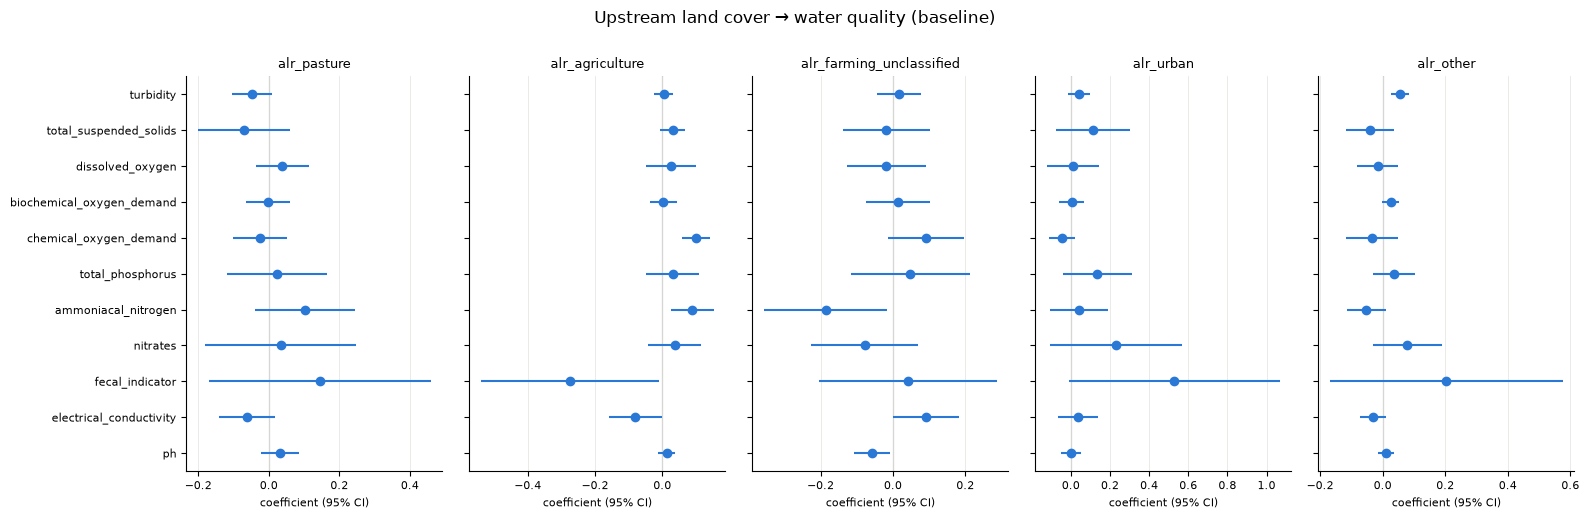

In [6]:
coefficient_plot(main, REGRESSORS, title="Upstream land cover → water quality (baseline)")

**Reading the results (run of 2026-10-21).** - **Significant at 5%** (8 of 55 land-cover coefficients, analytic Otto-3 SEs):
  - agriculture → COD +0.10, ammoniacal N +0.09, fecal indicator −0.27, conductivity −0.08;
  - unclassified farming → ammoniacal N −0.19, conductivity +0.09, pH −0.06;
  - "other" non-natural land → turbidity +0.05.
- **Pasture.** None of its coefficients reaches significance (turbidity −0.05,
  p ≈ 0.10).
- **Magnitudes.** The within-station SD of `alr_agriculture` is about 0.36, so the COD
  coefficient means about +3.6% COD per within-SD of agricultural expansion.
- **Fecal sign.** The negative fecal effect of agriculture matches a shift away from
  livestock and human waste sources as cropland replaces pasture or natural land.

## 4. Baseline: CONAMA 357 class-2 violations

Linear probability models in percentage points. Same specification and identifying-station rule as §3.

In [7]:
conama_fits = fit_all(EXCEEDANCE)
conama = tidy(conama_fits, "baseline")
pf.etable(list(conama_fits.values()), keep=REGRESSORS + INTERACTIONS)

GT(_tbl_data=   __index_level_0__         __index_level_1__                     0                    1                    2                       3                     4                    5                    6  \
0               coef               alr_pasture    0.185 <br> (0.611)  -0.401 <br> (0.663)  -0.287 <br> (0.328)     -0.152 <br> (0.717)    2.570 <br> (2.321)  -0.674 <br> (0.652)  -1.538 <br> (2.213)   
1               coef       alr_pasture × sro_7    0.187 <br> (0.125)  -0.003 <br> (0.058)  0.452* <br> (0.208)     -0.085 <br> (0.046)  0.561** <br> (0.206)   0.078 <br> (0.090)  -0.059 <br> (0.065)   
2               coef           alr_agriculture   -0.181 <br> (1.107)  -0.904 <br> (0.590)   0.205 <br> (0.283)     -0.697 <br> (0.578)    0.279 <br> (0.843)  -0.347 <br> (0.249)  -0.375 <br> (2.050)   
3               coef   alr_agriculture × sro_7   -0.198 <br> (0.123)  -0.065 <br> (0.097)  -0.075 <br> (0.214)  -0.132*** <br> (0.035)   -0.173 <br> (0.202)  0.133* <br> (0.062)   0.000 <br> (0.084)   
4               coef  alr_farming_unclassified    0.186 <br> (0.907)  -0.054 <br> (0.885)   0.031 <br> (0.523)      0.526 <br> (0.871)    0.499 <br> (2.306)   1.099 <br> (0.700)  -2.021 <br> (3.861)   
5               coef                 alr_urban    0.646 <br> (1.730)  -0.209 <br> (1.222)   0.441 <br> (0.766)     -1.081 <br> (0.849)    3.842 <br> (3.426)  -0.348 <br> (0.897)  -0.275 <br> (1.467)   
6               coef                 alr_other  1.572** <br> (0.509)   0.029 <br> (0.441)   0.368 <br> (0.336)      0.111 <br> (0.478)    2.353 <br> (1.593)   0.561 <br> (0.431)   1.731 <br> (1.351)   
7                 fe               biome_month                     x                    x                    x                       x                     x                    x                    x   
8                 fe               biome_year                      x                    x                    x                       x                     x                    x                    x   
9                 fe             station_code                      x                    x                    x                       x                     x                    x                    x   
10                fe  station_code^fecal_type                      -                    -                    -                       -                     -                    -                    -   
11             stats              Observations                99,635              159,197              148,268                 165,916                81,553               57,490               22,121   
12             stats                        R²                 0.522                0.479                0.257                   0.299                 0.459                0.616                0.477   

                       7  ...                       9                     10                   11                   12                       13                    14                     15                   16  \
0    -0.916 <br> (2.831)  ...  23.361*** <br> (3.214)     0.938 <br> (4.497)   1.014 <br> (1.919)  -1.768 <br> (2.509)      7.789 <br> (11.546)    7.879 <br> (5.362)    -3.820 <br> (4.262)   2.499 <br> (3.138)   
1    1.157* <br> (0.520)  ...   1.174*** <br> (0.307)  -0.723** <br> (0.227)   0.332 <br> (0.216)  0.411* <br> (0.177)      -0.250 <br> (0.239)   -0.041 <br> (0.122)  2.888*** <br> (0.727)   0.516 <br> (0.344)   
2    -2.700 <br> (1.480)  ...     -1.043 <br> (1.387)    -1.745 <br> (0.954)   0.221 <br> (0.457)   0.865 <br> (1.194)  -16.064*** <br> (3.649)   1.526* <br> (0.549)     0.444 <br> (1.478)   1.699 <br> (2.016)   
3    -0.641 <br> (0.412)  ...    -0.889* <br> (0.328)    0.393* <br> (0.152)  -0.131 <br> (0.090)  -0.214 <br> (0.193)      -0.046 <br> (0.292)   -0.147 <br> (0.162)    -0.918 <br> (0.682)   0.175 <br> (0.492)   
4   4.625** <br> (1.615)  ...      5.784 <br> (4.920)     0.292 <br> (3.171)  -1.687 <br> (1.

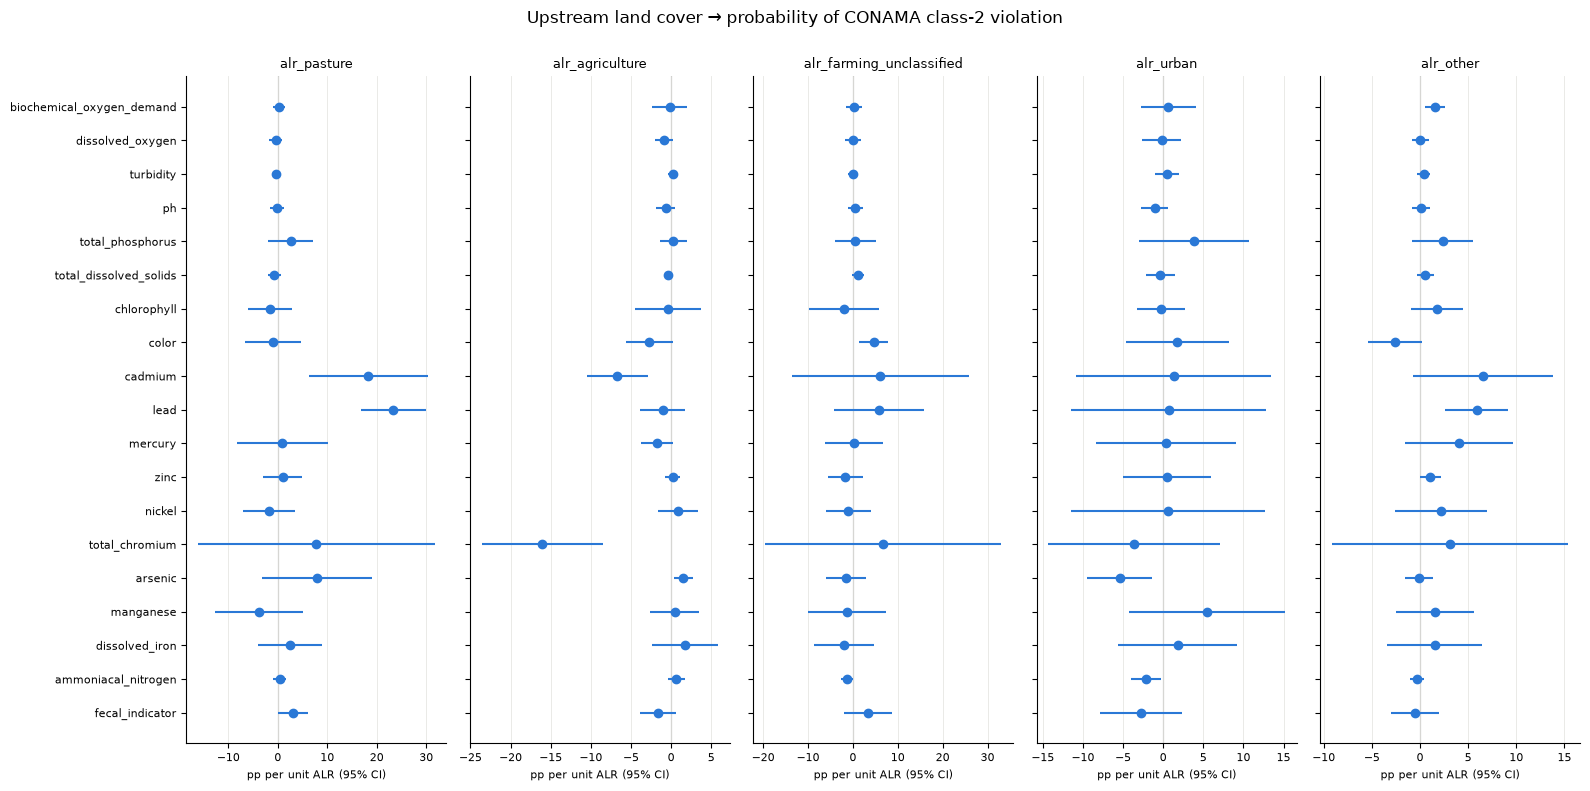

In [8]:
coefficient_plot(conama, REGRESSORS, title="Upstream land cover → probability of CONAMA class-2 violation",
                 xlabel="pp per unit ALR (95% CI)")

**Reading the results (run of 2026-10-21).** The strongest signals are for metals:
- **Pasture → lead and cadmium.** Pasture raises lead violations by +23 pp and cadmium
  violations by +18 pp per unit ALR. Per within-station SD (about 0.21), that is about
  +5 pp and +4 pp, against base rates of 28% and 23%.
- **Agriculture → fewer metal violations.** Chromium −16 pp and cadmium −7 pp.
- **Other effects.** "Other" non-natural land raises lead and BOD violations, and urban
  land lowers arsenic violations.
- **Small clusters.** The metal samples have only 22–35 Otto-3 basins, so these
  analytic p-values are optimistic; §5.7 bootstraps them.
- **Core outcomes.** Apart from the BOD effect of "other" land, their violation
  indicators (DO, turbidity, pH, phosphorus) are essentially unaffected, consistent
  with the continuous results.

## 5. Robustness

### 5.1 Station-year means
Removes intra-year variation (seasonality and sampling noise). Outcomes, controls and
the runoff interactions are averaged within station-year, separately per outcome so each
uses only the samples where it is observed. FE: station (× indicator type) + biome×year.

In [9]:
for regressor in P.RUNOFF_INTERACTED:
    df[f"{regressor}_x_{P.RUNOFF_CONTROL}"] = df[regressor] * df[P.RUNOFF_CONTROL]
PRODUCT_TERMS = [f"{regressor}_x_{P.RUNOFF_CONTROL}" for regressor in P.RUNOFF_INTERACTED]
RHS_STATION_YEAR = " + ".join(REGRESSORS + PRODUCT_TERMS + CONTROLS)


def station_year_means(outcome):
    sample = df[P.identifying_stations(df, outcome)]
    # otto_basin_l3 is constant within station; kept as a key so VCOV's cluster survives.
    keys = ["station_code", "year", "biome_year", "otto_basin_l3"] + (["fecal_type"] if "fecal_indicator" in outcome else [])
    return sample.groupby(keys, as_index=False)[[outcome] + REGRESSORS + PRODUCT_TERMS + CONTROLS].mean()


station_year_fits = {}
for outcome in CONTINUOUS:
    aggregated = station_year_means(outcome)
    formula = f"{outcome} ~ {RHS_STATION_YEAR} | {station_fe(outcome)} + biome_year"
    station_year_fits[outcome] = pf.feols(formula, data=aggregated, vcov=VCOV)
station_year = tidy(station_year_fits, "station-year means")

### 5.2 PPML on levels
Poisson pseudo-ML on the (trimmed) levels of the logged outcomes; keeps zeros and
non-detects that the log drops. Coefficients are on the same log scale as the baseline.

In [10]:
LEVEL_FOR_PPML = [c for c in P.CONTINUOUS_OUTCOMES if c not in P.LEVEL_OUTCOMES]
for column in LEVEL_FOR_PPML:
    values = df[column]
    df[f"lvl_{column}"] = values.where(values <= values.quantile(P.TRIM_QUANTILE))
ppml_fits = fit_all([f"lvl_{c}" for c in LEVEL_FOR_PPML], method="fepois")
ppml = tidy(ppml_fits, "PPML levels")
ppml["outcome"] = ppml["outcome"].str.replace("lvl_", "y_", regex=False)

### 5.3 Discharge as a dilution control
Discharge is downstream of land cover (runoff), so it is a mediator and excluded from the
baseline; controlling for it shows how much of the effect runs through flow.

In [11]:
discharge_fits = fit_all(CONTINUOUS, rhs=RHS + " + log_discharge")
discharge = tidy(discharge_fits, "+ log discharge")

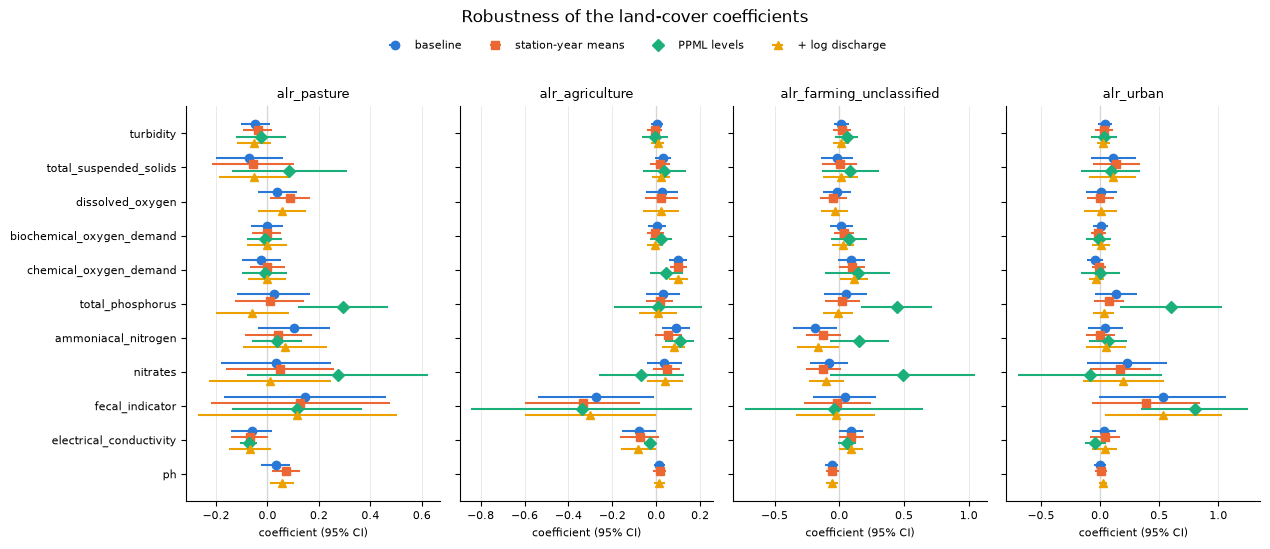

In [12]:
robustness = pd.concat([main, station_year, ppml, discharge], ignore_index=True)
coefficient_plot(robustness, ["alr_pasture", "alr_agriculture", "alr_farming_unclassified", "alr_urban"],
                 specs=["baseline", "station-year means", "PPML levels", "+ log discharge"],
                 title="Robustness of the land-cover coefficients")

**Reading the results (run of 2026-10-21).** - **Robust.** The agriculture effects on COD, fecal indicator and conductivity, and the
  unclassified-farming effects on conductivity and pH, are stable across station-year
  means, PPML on levels and the discharge control.
- **Discharge.** Controlling for it barely moves any coefficient, so the effects do not
  run through flow volume (dilution).
- **PPML differs for nutrients.** Its coefficients for total phosphorus and nitrates are
  larger and positive. Unlike the log model, PPML keeps zeros and non-detects and
  weights high concentrations. Unclassified farming → ammoniacal N even flips sign
  (−0.19 in logs vs +0.15 in PPML), so that result is not robust.
- **Overall.** Across all land-cover coefficients, the four specifications agree in sign
  68% of the time.

### 5.4 Distance bands
Separate ALR regressors for land within 0–50, 50–150 and 150–500 km upstream (the 500 km+
catch-all ring excluded). The sample is restricted to stations with land in every band.
Adjacent rings are correlated (0.87 within station), so expect wide intervals.

Stations with land in every band: 2,497 of 5,773


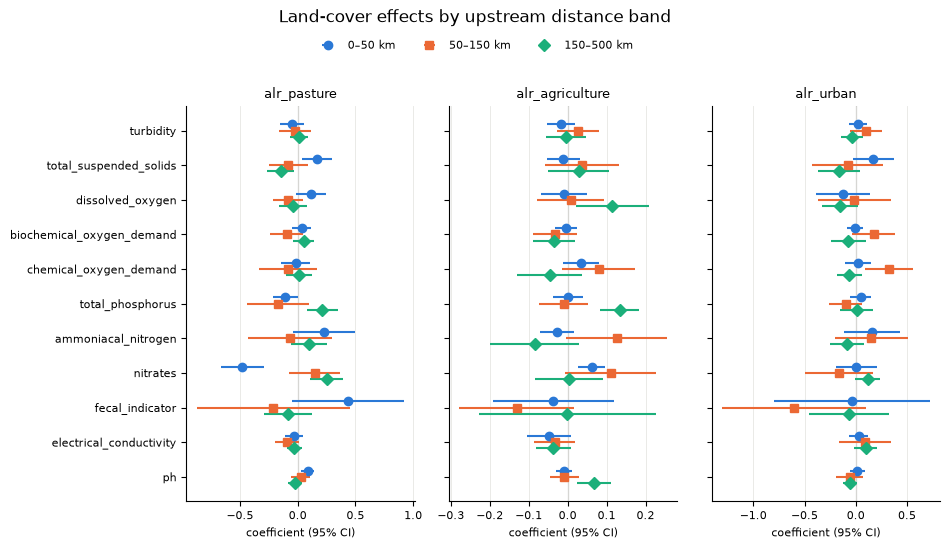

In [13]:
BANDED = [f"{regressor}__{band}" for band in P.DISTANCE_BANDS for regressor in REGRESSORS]
band_sample = df.dropna(subset=BANDED)
print(f"Stations with land in every band: {band_sample.station_code.nunique():,} of {df.station_code.nunique():,}")
band_fits = fit_all(CONTINUOUS, data=band_sample, rhs=" + ".join(BANDED + CONTROLS))
bands = tidy(band_fits, "bands")

band_long = bands[bands["Coefficient"].isin(BANDED)].copy()
band_long[["regressor", "band"]] = band_long["Coefficient"].str.split("__", expand=True)
band_long["spec"] = band_long["band"].map({b: f"{lo}–{hi} km" for b, (lo, hi) in P.DISTANCE_BANDS.items()})
band_long["Coefficient"] = band_long["regressor"]
coefficient_plot(band_long, ["alr_pasture", "alr_agriculture", "alr_urban"],
                 specs=[f"{lo}–{hi} km" for lo, hi in P.DISTANCE_BANDS.values()],
                 title="Land-cover effects by upstream distance band")

**Reading the results (run of 2026-10-21).** - **No reliable distance gradient.** Only 17 of 275 band coefficients are significant at
  5%, about what chance produces (≈ 14).
- **Sign reversals.** Several significant pairs reverse sign between near and far bands
  (pasture → nitrates −0.48 at 0–50 km vs +0.25 at 150–500 km; pasture → TSS +0.17 vs
  −0.15). That is consistent with the high correlation between rings (descriptives §7)
  rather than a real gradient.
- **Implication.** The data cannot pin down the distance kernel, so the single
  capped-kernel exposure is the appropriate baseline. The sample is also restricted to
  the 2,497 stations with land in every band.

### 5.5 Heterogeneity by biome
Biome-specific slopes for pasture and agriculture, for the outcomes measured in every
biome (turbidity, DO, pH, EC). Other regressors keep a common slope.

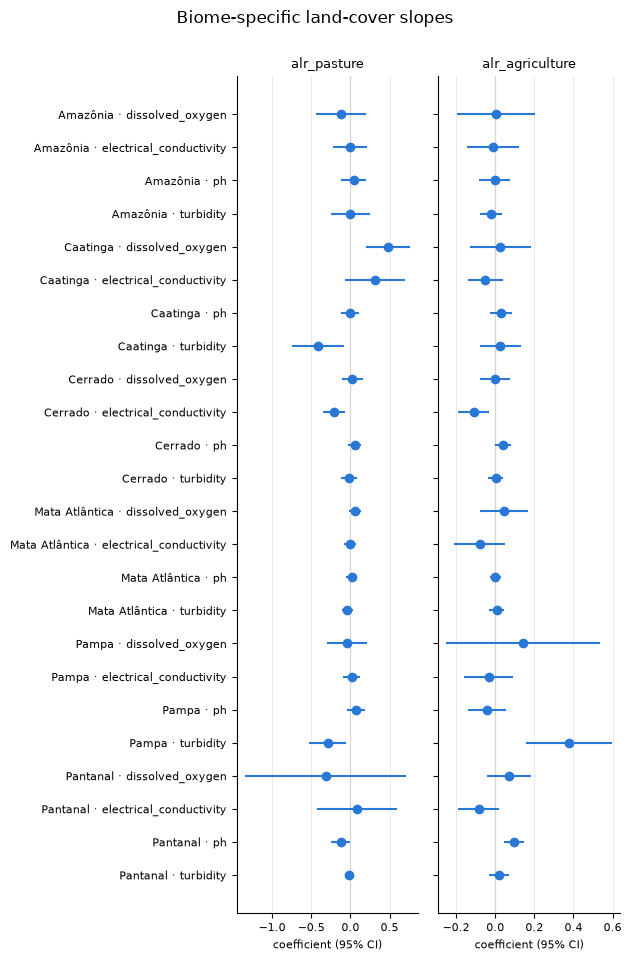

In [14]:
HETEROGENEITY_OUTCOMES = ["y_turbidity", "y_dissolved_oxygen", "y_ph", "y_electrical_conductivity"]
other_regressors = [r for r in REGRESSORS if r not in ("alr_pasture", "alr_agriculture")]
RHS_BIOME = " + ".join(["i(biome, alr_pasture)", "i(biome, alr_agriculture)"] + other_regressors + CONTROLS)
biome_fits = fit_all(HETEROGENEITY_OUTCOMES, rhs=RHS_BIOME)
biome = tidy(biome_fits, "by biome")

biome_long = biome[biome["Coefficient"].str.startswith("biome::")].copy()
parts = biome_long["Coefficient"].str.extract(r"biome::(?P<biome>.+):(?P<regressor>alr_\w+)$")
biome_long["Coefficient"] = parts["regressor"]
biome_long["outcome"] = parts["biome"] + " · " + biome_long["outcome"].str.removeprefix("y_")
coefficient_plot(biome_long.sort_values("outcome"), ["alr_pasture", "alr_agriculture"], specs=["by biome"],
                 title="Biome-specific land-cover slopes")

**Reading the results (run of 2026-10-21).** 8 of 48 biome-specific slopes are significant (about 2.4 expected by chance), so there
is some heterogeneity, but without a consistent pattern:
- Caatinga pasture is associated with lower turbidity (−0.41) and higher DO (+0.48).
- Cerrado pasture and agriculture with lower conductivity.
- Pampa agriculture with higher turbidity (+0.38).
- The Mata Atlântica, which dominates the pooled sample, has precise nulls throughout.

The pooled coefficients therefore mostly reflect a Mata Atlântica null, combined with
offsetting effects in smaller biomes.

### 5.6 Inference: clustering level
Standard errors of the baseline continuous models under alternative clusterings,
recomputed on the same fits. Ratios are relative to the Otto level-3 baseline.

In [15]:
CLUSTERINGS = {
    "station + year": {"CRV1": "station_code+year"},
    "Otto 2": {"CRV1": "otto_basin_l2"},
    "Otto 3 (baseline)": VCOV,
    "Otto 4": {"CRV1": "otto_basin_l4"},
    "Otto 3 + year": {"CRV1": "otto_basin_l3+year"},
}
rows = []
for outcome, model in main_fits.items():
    for label, vcov in CLUSTERINGS.items():
        model.vcov(vcov)
        table = model.tidy().loc[REGRESSORS]
        rows.append(table.assign(outcome=outcome, clustering=label, n_clusters=model._G[0]).reset_index())
    model.vcov(VCOV)  # restore the baseline inference
inference = pd.concat(rows, ignore_index=True)

standard_errors = inference.pivot_table(index=["outcome", "Coefficient"], columns="clustering", values="Std. Error")
se_ratio = standard_errors.div(standard_errors["Otto 3 (baseline)"], axis=0)
display(se_ratio[list(CLUSTERINGS)].describe(percentiles=[0.1, 0.5, 0.9]).T.round(2))
display(inference.groupby("clustering").agg(
    clusters_median=("n_clusters", "median"),
    significant_5pct=("Pr(>|t|)", lambda p: int((p < 0.05).sum())),
    tests=("Pr(>|t|)", "size"),
).loc[list(CLUSTERINGS)])

,count,mean,std,min,10%,50%,90%,max
clustering,,,,,,,,
station + year,55,0.93,0.25,0.52,0.68,0.9,1.21,1.93
Otto 2,55,0.86,0.28,0.19,0.51,0.91,1.21,1.33
Otto 3 (baseline),55,1,0,1,1,1,1,1
Otto 4,55,0.94,0.16,0.68,0.75,0.93,1.14,1.47
Otto 3 + year,55,1.07,0.12,0.87,0.98,1.03,1.21,1.48


,clusters_median,significant_5pct,tests
clustering,,,
station + year,40,11,55
Otto 2,18,11,55
Otto 3 (baseline),86,8,55
Otto 4,370,8,55
Otto 3 + year,40,5,55


**Reading the results (run of 2026-10-21).** - **Station + year was too small.** Otto-3 standard errors are larger than station +
  year ones for most coefficients (median ratio 0.90), confirming that errors are
  correlated along rivers.
- **Otto 4.** It gives similar SEs (0.93×), so level 3 is not too coarse.
- **Otto 2.** It gives smaller SEs, but has only 18 clusters in the median sample, too
  few for reliable analytic inference.
- **Otto 3 + year.** Adding year as a second cluster dimension raises SEs by about 3%.
- **Significant counts.** They fall from 11 (station + year) to 8 (Otto 3) and 5
  (Otto 3 + year).

### 5.7 Wild-cluster bootstrap
Analytic cluster-robust p-values over-reject with few clusters, and some samples
(metals) have only a few dozen Otto-3 basins. Restricted wild-cluster bootstrap
(WCR, 9,999 reps, Rademacher weights; Webb below 12 clusters) for every land-cover
coefficient in both baseline families, run on the FE-demeaned design
(`src/analysis/inference.py`).

In [16]:
BOOT_REPS = 9_999
boot_rows = []
for family, fits in [("continuous", main_fits), ("conama", conama_fits)]:
    for outcome, model in fits.items():
        analytic = model.tidy()
        for regressor in REGRESSORS:
            row = wild_cluster_bootstrap(model, regressor, cluster="otto_basin_l3", reps=BOOT_REPS, seed=20261021)
            row["outcome"], row["family"] = outcome, family
            row["Estimate"] = analytic.loc[regressor, "Estimate"]
            row["p_analytic"] = analytic.loc[regressor, "Pr(>|t|)"]
            boot_rows.append(row)
bootstrap = pd.DataFrame(boot_rows)

display(bootstrap.groupby("family").agg(
    tests=("p_wcb", "size"),
    clusters_min=("n_clusters", "min"),
    clusters_median=("n_clusters", "median"),
    analytic_5pct=("p_analytic", lambda p: int((p < 0.05).sum())),
    bootstrap_5pct=("p_wcb", lambda p: int((p < 0.05).sum())),
    bootstrap_1pct=("p_wcb", lambda p: int((p < 0.01).sum())),
))
display(bootstrap[(bootstrap["p_wcb"] < 0.05) | (bootstrap["p_analytic"] < 0.05)]
        .sort_values(["family", "p_wcb"])
        [["family", "outcome", "Coefficient", "Estimate", "p_analytic", "p_wcb", "n_clusters", "weights"]])

,tests,clusters_min,clusters_median,analytic_5pct,bootstrap_5pct,bootstrap_1pct
family,,,,,,
conama,95,19,50,11,8,3
continuous,55,77,86,8,6,2


,family,outcome,Coefficient,Estimate,p_analytic,p_wcb,n_clusters,weights
128,conama,exceed_arsenic,alr_urban,-5.427,0.01074,0.0015,22,rademacher
100,conama,exceed_lead,alr_pasture,23.36,2.048e-08,0.0039,35,rademacher
104,conama,exceed_lead,alr_other,5.896,0.0008228,0.009101,35,rademacher
95,conama,exceed_cadmium,alr_pasture,18.28,0.004333,0.0117,26,rademacher
121,conama,exceed_total_chromium,alr_agriculture,-16.06,0.0002063,0.024,24,rademacher
59,conama,exceed_biochemical_oxygen_demand,alr_other,1.572,0.002709,0.0263,89,rademacher
96,conama,exceed_cadmium,alr_agriculture,-6.705,0.001148,0.0411,26,rademacher
142,conama,exceed_ammoniacal_nitrogen,alr_farming_unclassified,-1.28,0.05064,0.0484,88,rademacher
92,conama,exceed_color,alr_farming_unclassified,4.625,0.005691,0.07141,64,rademacher
145,conama,exceed_fecal_indicator,alr_pasture,3.111,0.04285,0.141,87,rademacher


**Reading the results (run of 2026-10-21).** **What survives the bootstrap.**
- *Survive:* agriculture → COD (p = 0.004), "other" → turbidity (0.002), pasture → lead
  violations (0.004) and cadmium violations (0.012), agriculture → chromium violations
  (0.024), urban → arsenic violations (0.002).
- *Lose significance:* pasture → fecal violations (0.14), urban → ammonia violations
  (0.36), agriculture → arsenic violations (0.15).
- *Where it matters:* for the metal outcomes (19–35 basins) the bootstrap p-values are
  orders of magnitude larger than the analytic ones (lead–pasture: 2e-8 analytic vs
  0.004 bootstrap). For the core outcomes (77–183 basins) the two agree closely.

## 6. Mining arm

Mining is a local source, so its exposure is measured within **50 km** upstream, and the
model is estimated only on the **1,205 stations with any mining in that reach** over
their sampled years. Two mining regressors are added to the baseline specification:

- `mining_present_50`: mining appears in the 50 km reach (identified from stations where
  it switches on or off);
- `mining_pp_50`: percentage points of the 50 km reach under mining (intensity).

Outcomes are those where a mining signature is expected: sediment and ionic load
(turbidity, TSS, conductivity), pH, DO, and CONAMA exceedances for turbidity and metals.
The metal samples cover only 12–20 Otto-3 basins, so §6.2's wild-cluster bootstrap
p-values are the ones to read.

In [17]:
mining = df[df[P.MINING_STATION]].copy()
presence = mining.groupby("station_code")[P.MINING_PRESENT].agg(["min", "max"])
switchers = presence.index[(presence["min"] == 0) & (presence["max"] == 1)]
print(f"Mining stations: {mining.station_code.nunique():,}; switching presence: {len(switchers):,}; "
      f"samples: {len(mining):,}")
display(mining.drop_duplicates("station_code")["biome"].value_counts().rename("mining stations").to_frame().T)
display(mining.loc[mining[P.MINING_PRESENT] == 1, P.MINING_SHARE_PP]
        .describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).rename("mined share of 50 km reach (pp), where present").to_frame().T)

Mining stations: 1,205; switching presence: 158; samples: 46,824


biome,Mata Atlântica,Cerrado,Amazônia,Caatinga,Pampa,Pantanal
mining stations,654,257,176,90,16,12


,count,mean,std,min,25%,50%,75%,90%,99%,max
"mined share of 50 km reach (pp), where present",4.286e+04,0.4514,1.325,3.49e-05,0.01594,0.07868,0.2835,1.065,5.756,33.34


### 6.1 Estimates

In [18]:
MINING_OUTCOMES = ([f"y_{c}" for c in P.MINING_CONTINUOUS_OUTCOMES]
                   + [f"exceed_{c}" for c in P.MINING_EXCEEDANCE_OUTCOMES])
RHS_MINING = " + ".join(P.MINING_REGRESSORS) + " + " + RHS
mining_fits = fit_all(MINING_OUTCOMES, data=mining, rhs=RHS_MINING)
mining_table = tidy(mining_fits, "mining arm")
pf.etable(list(mining_fits.values()), keep=P.MINING_REGRESSORS)

GT(_tbl_data=  __index_level_0__  __index_level_1__                    0                    1                    2                    3                    4                       5                    6                   7  \
0              coef  mining_present_50   0.026 <br> (0.066)  -0.086 <br> (0.057)  -0.130 <br> (0.091)   0.003 <br> (0.031)  -0.227 <br> (0.152)     -0.412 <br> (1.007)   8.129 <br> (4.447)  3.951 <br> (2.240)   
1              coef       mining_pp_50  -0.059 <br> (0.037)   0.022 <br> (0.017)  -0.107 <br> (0.082)  -0.010 <br> (0.022)  -0.017 <br> (0.040)  -1.968*** <br> (0.574)  -0.160 <br> (0.939)  1.092 <br> (2.051)   
2                fe        biome_month                    x                    x                    x                    x                    x                       x                    x                   x   
3                fe        biome_year                     x                    x                    x                    x                    x                       x                    x                   x   
4                fe      station_code                     x                    x                    x                    x                    x                       x                    x                   x   
5             stats       Observations               38,227               11,409               26,662               42,368               41,238                  39,075                6,334               8,669   
6             stats                 R²                0.529                0.571                0.664                 0.46                0.712                   0.272                0.637               0.549   

                        8                      9                   10                    11                      12                   13                   14  
0  13.704*** <br> (2.071)  -4.375** <br> (1.353)   1.535 <br> (0.840)    6.041 <br> (6.010)      0.540 <br> (0.859)  -2.831 <br> (3.297)  -2.172 <br> (4.286)  
1    -12.712 <br> (9.472)    -0.188 <br> (0.652)  -0.636 <br> (0.442)  -11.335 <br> (7.954)  -4.667*** <br> (0.674)   3.782 <br> (3.703)  -0.478 <br> (0.772)  
2                       x                      x                    x                     x                       x                    x                    x  
3                       x                      x                    x                     x                       x                    x                    x  
4                       x                      x                    x                     x                       x                    x                    x  
5                   5,530                  6,006                9,074                 4,372                   3,600                5,102                6,374  
6                   0.493                  0.164                0.416                 0.659                   0.671                0.537                0.362  , _body=<great_tables._gt_data.Body object at 0x7fb9b0168510>, _boxhead=Boxhead([ColInfo(var='__index_level_0__', type=<ColInfoTypeEnum.row_group: 3>, column_label='__index_level_0__', column_align='center', column_width=None), ColInfo(var='__index_level_1__', type=<ColInfoTypeEnum.stub: 2>, column_label='__index_level_1__', column_align='center', column_width=None), ColInfo(var='0', type=<ColInfoTypeEnum.default: 1>, column_label='(1)', column_align='center', column_width=None), ColInfo(var='1', type=<ColInfoTypeEnum.default: 1>, column_label='(2)', column_align='center', column_width=None), ColInfo(var='2', type=<ColInfoTypeEnum.default: 1>, column_label='(3)', column_align='center', column_width=None), ColInfo(var='3', type=<ColInfoTypeEnum.default: 1>, column_label='(4)', column_align='center', column_width=None), ColInfo(var='4', type=<ColInfoTypeEnum.default: 1>, column_label='(5)', column_align='center', column_width=None), ColInfo(var='5', type=<ColInfoTypeEnum.default: 1>, column_label='

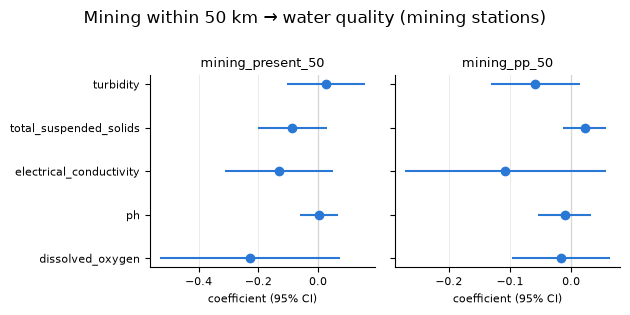

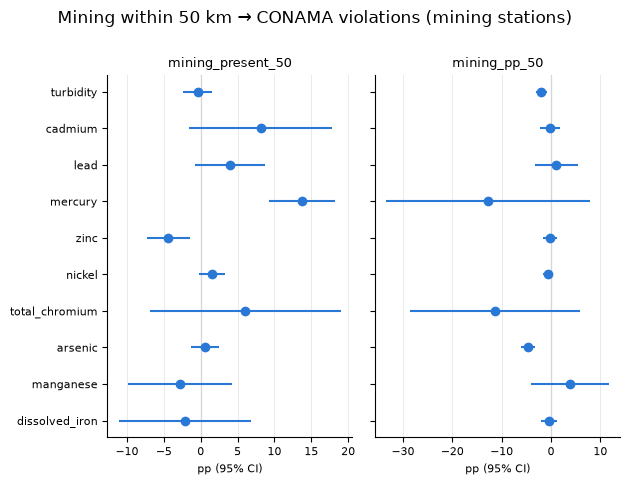

In [19]:
coefficient_plot(mining_table[mining_table["outcome"].str.startswith("y_")], P.MINING_REGRESSORS,
                 title="Mining within 50 km → water quality (mining stations)")
coefficient_plot(mining_table[mining_table["outcome"].str.startswith("exceed_")], P.MINING_REGRESSORS,
                 title="Mining within 50 km → CONAMA violations (mining stations)",
                 xlabel="pp (95% CI)")

**Reading the results (run of 2026-10-21).** The mining stations are 1,205 stations, 46,824 samples, mostly in Mata Atlântica (654)
and Cerrado (257). 158 of them switch mining presence; where present, mining covers a
median 0.08 pp of the 50 km reach.
- **Presence.** Mining appearing upstream raises mercury violations by about 14 pp,
  lead violations by about 4 pp and cadmium violations by about 8 pp, and lowers zinc
  violations by about 4 pp.
- **Intensity.** The extra mined share shows no positive effect, and a negative one on
  turbidity violations (−2 pp per pp mined). Effects come from mining appearing, not
  from its size, consistent with small, point-like operations.
- **Continuous outcomes.** No significant mining effects.

### 6.2 Wild-cluster bootstrap for the mining coefficients

In [20]:
mining_boot_rows = []
for outcome, model in mining_fits.items():
    analytic = model.tidy()
    for regressor in P.MINING_REGRESSORS:
        row = wild_cluster_bootstrap(model, regressor, cluster="otto_basin_l3", reps=BOOT_REPS, seed=20261021)
        row["outcome"], row["family"] = outcome, "mining"
        row["Estimate"] = analytic.loc[regressor, "Estimate"]
        row["p_analytic"] = analytic.loc[regressor, "Pr(>|t|)"]
        mining_boot_rows.append(row)
mining_boot = pd.DataFrame(mining_boot_rows)
display(mining_boot[["outcome", "Coefficient", "Estimate", "p_analytic", "p_wcb", "n_clusters", "weights"]]
        .sort_values(["Coefficient", "p_wcb"]))

,outcome,Coefficient,Estimate,p_analytic,p_wcb,n_clusters,weights
11,exceed_turbidity,mining_pp_50,-1.968,0.0009735,0.0187,77,rademacher
25,exceed_arsenic,mining_pp_50,-4.667,2.513e-05,0.03613,12,rademacher
1,y_turbidity,mining_pp_50,-0.05876,0.1121,0.0458,77,rademacher
3,y_total_suspended_solids,mining_pp_50,0.02202,0.2142,0.176,41,rademacher
23,exceed_total_chromium,mining_pp_50,-11.33,0.1777,0.2931,14,rademacher
5,y_electrical_conductivity,mining_pp_50,-0.1074,0.1958,0.382,63,rademacher
21,exceed_nickel,mining_pp_50,-0.6364,0.1715,0.3913,15,rademacher
17,exceed_mercury,mining_pp_50,-12.71,0.2044,0.5002,13,rademacher
29,exceed_dissolved_iron,mining_pp_50,-0.4778,0.5431,0.5325,20,rademacher
27,exceed_manganese,mining_pp_50,3.782,0.3244,0.5885,15,rademacher


**Reading the results (run of 2026-10-21).** **Which mining effects survive the bootstrap** (12–20 basins for metals):
- *Survive:* presence → mercury violations (p = 0.004) is the robust mining result.
  Presence → lead (0.045) and zinc (0.019, negative) survive more narrowly. So does
  intensity → turbidity and arsenic violations (both negative, p = 0.02 and 0.04).
- *Lose significance:* presence → cadmium (0.11).
- *Multiple testing:* with 30 tests and about 1.5 false positives expected at 5%, the
  mercury result is the one to emphasize.

### 6.3 Mining in the full-sample model
Adds 200 km `alr_mining` to the baseline on all stations. This shows what the main model
would attribute to mining, and whether leaving mining out moves the other land-cover
coefficients.

In [21]:
with_mining_fits = fit_all(MINING_OUTCOMES, rhs=RHS + " + alr_mining")
with_mining = tidy(with_mining_fits, "baseline + alr_mining")
display(with_mining[with_mining["Coefficient"] == "alr_mining"]
        [["outcome", "Estimate", "Std. Error", "Pr(>|t|)", "n_obs"]].set_index("outcome"))

baseline_all = tidy(fit_all(MINING_OUTCOMES), "baseline")
shift = (baseline_all[baseline_all["Coefficient"].isin(REGRESSORS)]
         .merge(with_mining[with_mining["Coefficient"].isin(REGRESSORS)],
                on=["outcome", "Coefficient"], suffixes=("_baseline", "_with_mining")))
shift["shift_in_se"] = (shift["Estimate_with_mining"] - shift["Estimate_baseline"]) / shift["Std. Error_baseline"]
display(shift["shift_in_se"].abs().describe(percentiles=[0.5, 0.9]).rename("|coefficient shift| in baseline SEs").to_frame().T)

,Estimate,Std. Error,Pr(>|t|),n_obs
outcome,,,,
y_turbidity,0.003461,0.0304,0.9095,145455
y_total_suspended_solids,0.04779,0.06819,0.4853,37449
y_electrical_conductivity,0.08302,0.04854,0.08908,98286
y_ph,0.0004947,0.02406,0.9836,165751
y_dissolved_oxygen,-0.06796,0.05516,0.2195,159013
exceed_turbidity,-0.9716,0.5334,0.0702,148268
exceed_cadmium,0.9395,1.923,0.6294,13335
exceed_lead,2.673,2.6,0.3111,18997
exceed_mercury,-1.335,2.188,0.547,17280


,count,mean,std,min,50%,90%,max
|coefficient shift| in baseline SEs,75,0.05494,0.07089,9.225e-05,0.02532,0.1845,0.3284


**Reading the results (run of 2026-10-21).** - **Full sample.** 200 km `alr_mining` is significant for only one outcome
  (arsenic violations, negative), so the broad upstream mining share carries little
  signal outside the mining stations.
- **Omission check.** Adding it moves the other land-cover coefficients by a median
  0.03 and at most 0.33 of their SEs. Omitting mining from the baseline therefore does
  not bias the other estimates.

## 7. Results export

In [22]:
results = pd.concat([main.assign(family="continuous"), conama.assign(family="conama"),
                     inference.rename(columns={"clustering": "spec"}).assign(family="inference"),
                     station_year.assign(family="continuous"), ppml.assign(family="continuous"),
                     discharge.assign(family="continuous"), bands.assign(family="continuous"),
                     biome.assign(family="continuous"), mining_table.assign(family="mining"),
                     with_mining.assign(family="mining")], ignore_index=True)
results.to_csv(RESULTS_DIR / "coefficients.csv", index=False)
pd.concat([bootstrap, mining_boot], ignore_index=True).to_csv(RESULTS_DIR / "wild_cluster_bootstrap.csv", index=False)
print(f"{len(results):,} coefficient rows -> {RESULTS_DIR.relative_to(PROJECT_ROOT) / 'coefficients.csv'}")

2,253 coefficient rows -> output/analysis/pollution/coefficients.csv
